<a href="https://colab.research.google.com/github/zatilhidayah/Final-Year-Project-2021/blob/main/KEPUTUSAN_BP_%26_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from google.colab import files
uploaded = files.upload()

# Mengimport Data
import numpy as np
import pandas as pd
import io
data = pd.read_csv(io.BytesIO(uploaded['Top Glove New.csv']))

data.head(3)

Saving Top Glove New.csv to Top Glove New (1).csv


,Date,Price,Open,High,Low,Vol.,Change %
0,2018-06-01,1.74,1.71,1.76,1.71,22.14M,1.75%
1,2018-06-04,1.78,1.75,1.78,1.73,42.44M,2.30%
2,2018-06-05,1.78,1.78,1.80,1.78,25.06M,0.00%


In [ ]:
data.shape

(755, 7)

In [ ]:
data.set_index('Date', inplace=True)
data.head()

,Price,Open,High,Low,Vol.,Change %
Date,,,,,,
2018-06-01,1.74,1.71,1.76,1.71,22.14M,1.75%
2018-06-04,1.78,1.75,1.78,1.73,42.44M,2.30%
2018-06-05,1.78,1.78,1.80,1.78,25.06M,0.00%
2018-06-06,1.78,1.78,1.79,1.77,13.95M,0.00%
2018-06-07,1.80,1.80,1.82,1.78,24.30M,1.12%


Graf Harga Saham Syarikat Top Glove

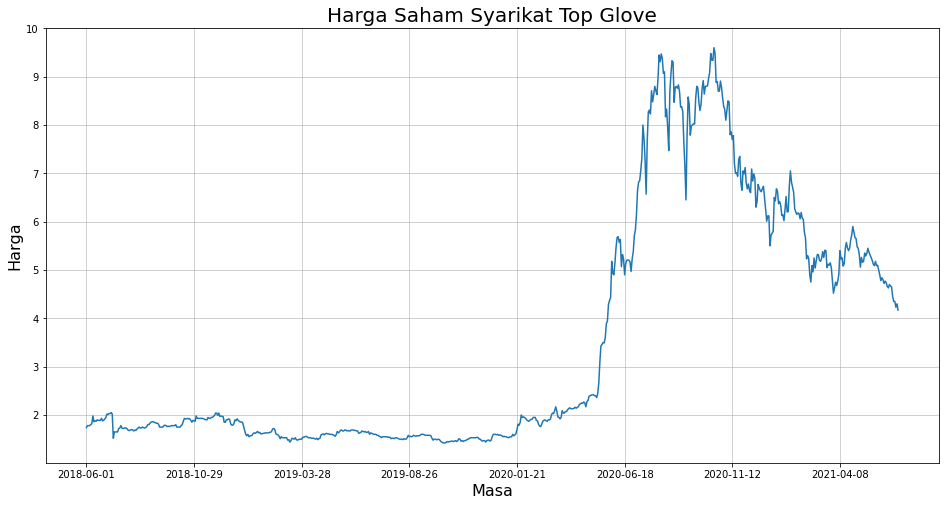

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot the close price
data['Price'].plot(figsize=(16,8))

# Define the label for the title of the figure
plt.title("Harga Saham Syarikat Top Glove", fontsize=20)

# Define the labels for x-axis and y-axis
plt.ylabel('Harga', fontsize=16)
plt.xlabel('Masa', fontsize=16)

# Plot the grid lines
plt.grid(which="major", color='#A3A3A3', linestyle='-', linewidth=0.5)

# Show the plot
plt.show()

In [ ]:
# Set Data yang Digunakan

import numpy as np
import pandas as pd

# Setting the random seed to a fixed number
import random
random.seed(42)

# Importing the dataset
data = data[['Open', 'High', 'Low', 'Price']]

# Price is a Close Price
data.head()

,Open,High,Low,Price
Date,,,,
2018-06-01,1.71,1.76,1.71,1.74
2018-06-04,1.75,1.78,1.73,1.78
2018-06-05,1.78,1.80,1.78,1.78
2018-06-06,1.78,1.79,1.77,1.78
2018-06-07,1.80,1.82,1.78,1.80


Pemboleh Ubah Baharu

In [ ]:
# Preparing the new input variables in dataset
data['H-L'] = data['High'] - data['Low']
data['O-C'] = data['Price'] - data['Open']
data['3day MA'] = data['Price'].shift(1).rolling(window = 3).mean()
data['10day MA'] = data['Price'].shift(1).rolling(window = 10).mean()
data['30day MA'] = data['Price'].shift(1).rolling(window = 30).mean()
data['Std_dev']= data['Price'].rolling(5).std()


# Importing the dataset
dataset = data[['H-L', 'O-C', '3day MA', '10day MA', '30day MA', 'Std_dev', 'Price']]
dataset = dataset.dropna()
dataset

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price
Date,,,,,,,
2018-07-16,0.08,0.07,1.650000,1.826,1.856667,0.031305,1.72
2018-07-17,0.06,0.00,1.673333,1.797,1.856000,0.041231,1.73
2018-07-18,0.06,0.04,1.700000,1.767,1.854333,0.055946,1.78
2018-07-19,0.10,-0.05,1.743333,1.742,1.854333,0.046583,1.73
2018-07-20,0.04,-0.01,1.746667,1.710,1.852667,0.025100,1.72
...,...,...,...,...,...,...,...
2021-06-24,0.16,-0.10,4.590000,4.679,5.002000,0.154855,4.35
2021-06-25,0.12,-0.01,4.483333,4.634,4.971667,0.157099,4.35
2021-06-28,0.15,-0.12,4.383333,4.597,4.944667,0.157099,4.23


In [ ]:
# Bilangan setiap baris (rows) and lajur (columns) dalam set data
dataset.shape

(725, 7)

**Rambatan Belakang**

In [ ]:
# Model BP-ANN (Rambatan Belakang)
# Create two data frames storing the input and the output variables
x = dataset.iloc[:, 0:6]
y = dataset.iloc[:, -1]

print(x)
print(y)

             H-L   O-C   3day MA  10day MA  30day MA   Std_dev
Date                                                          
2018-07-16  0.08  0.07  1.650000     1.826  1.856667  0.031305
2018-07-17  0.06  0.00  1.673333     1.797  1.856000  0.041231
2018-07-18  0.06  0.04  1.700000     1.767  1.854333  0.055946
2018-07-19  0.10 -0.05  1.743333     1.742  1.854333  0.046583
2018-07-20  0.04 -0.01  1.746667     1.710  1.852667  0.025100
...          ...   ...       ...       ...       ...       ...
2021-06-24  0.16 -0.10  4.590000     4.679  5.002000  0.154855
2021-06-25  0.12 -0.01  4.483333     4.634  4.971667  0.157099
2021-06-28  0.15 -0.12  4.383333     4.597  4.944667  0.157099
2021-06-29  0.15  0.08  4.310000     4.543  4.913000  0.080498
2021-06-30  0.18 -0.13  4.293333     4.499  4.878000  0.078740

[725 rows x 6 columns]
Date
2018-07-16    1.72
2018-07-17    1.73
2018-07-18    1.78
2018-07-19    1.73
2018-07-20    1.72
              ... 
2021-06-24    4.35
2021-06-25    4.35


In [ ]:
# Get the number of rows to train the model
import math
training_data_len = math.ceil(len(dataset) * 0.8)
training_data_len

580

In [ ]:
# Splitting the dataset
split = int(len(dataset)*0.8)
x_train, x_test, y_train, y_test = x[:split], x[split:], y[:split], y[split:]

print('x_train shape: {}'.format(x_train.shape))
print('y_train shape: {}'.format(y_train.shape))
print('x_test shape: {}'.format(x_test.shape))
print('y_test shape: {}'.format(y_test.shape))

x_train shape: (580, 6)
y_train shape: (580,)
x_test shape: (145, 6)
y_test shape: (145,)


In [ ]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

# Build the Backpropagation
import tensorflow as tf

model = tf.keras.models.Sequential()

# Input layer ada 6 node kerana menggunakan 6 variable baru
model.add(tf.keras.layers.Dense(units=6))

# Hidden layer (tidak kesah letak node berapa)
model.add(tf.keras.layers.Dense(units=10))

# Output layer
model.add(tf.keras.layers.Dense(units=1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(x_train, y_train, epochs=100, batch_size=64)

Epoch 1/100
10/10 [==============================] - 0s 2ms/step - loss: 17.2679
Epoch 2/100
10/10 [==============================] - 0s 2ms/step - loss: 15.7630
Epoch 3/100
10/10 [==============================] - 0s 2ms/step - loss: 14.3790
Epoch 4/100
10/10 [==============================] - 0s 2ms/step - loss: 13.1471
Epoch 5/100
10/10 [==============================] - 0s 2ms/step - loss: 11.9611
Epoch 6/100
10/10 [==============================] - 0s 2ms/step - loss: 10.7594
Epoch 7/100
10/10 [==============================] - 0s 2ms/step - loss: 9.5363
Epoch 8/100
10/10 [==============================] - 0s 2ms/step - loss: 8.4428
Epoch 9/100
10/10 [==============================] - 0s 2ms/step - loss: 7.3863
Epoch 10/100
10/10 [==============================] - 0s 2ms/step - loss: 6.4804
Epoch 11/100
10/10 [==============================] - 0s 2ms/step - loss: 5.6574
Epoch 12/100
10/10 [==============================] - 0s 3ms/step - loss: 4.9011
Epoch 13/100
10/10 [===========

In [ ]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_5 (Dense)             (None, 6)                 42        
                                                                 
 dense_6 (Dense)             (None, 10)                70        
                                                                 
 dense_7 (Dense)             (None, 1)                 11        
                                                                 
Total params: 123
Trainable params: 123
Non-trainable params: 0
_________________________________________________________________


In [ ]:
# Get the models predicted price values
predictions = model.predict(x_test)
predictions.shape

(145, 1)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.


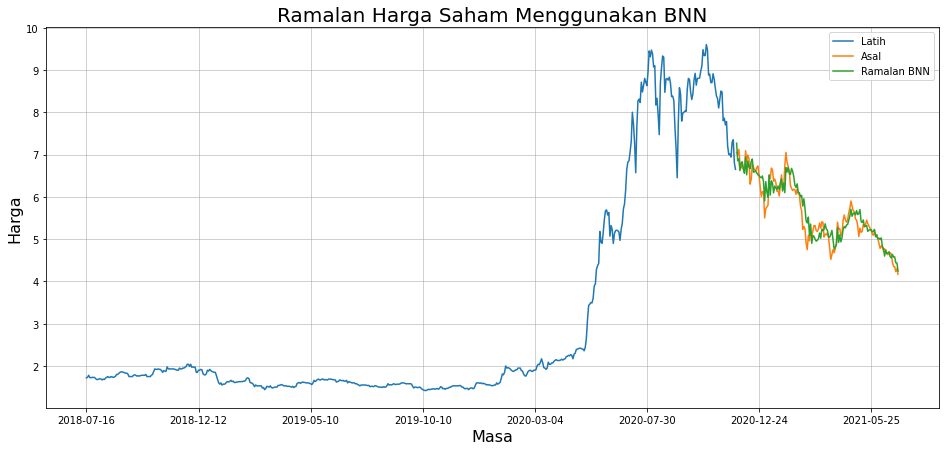

In [ ]:
# Plot the data
train = dataset[:training_data_len]
valid = dataset[training_data_len:]
valid['Predictions'] = predictions

# Visualize the data
plt.figure(figsize=(16,7))
plt.title('Ramalan Harga Saham Menggunakan BNN', fontsize=20)
plt.xticks(np.arange(0,755,100))
plt.xlabel('Masa', fontsize=16)
plt.ylabel('Harga', fontsize=16)
plt.plot(train['Price'])
plt.plot(valid[['Price', 'Predictions']])
plt.legend(['Latih', 'Asal', 'Ramalan BNN'], loc='upper right')

# Plot the grid lines
plt.grid(which="major", color='#A3A3A3', linestyle='-', linewidth=0.5)
plt.show()

In [ ]:
data_bp = dataset
data_bp['predictions'] = np.NaN
data_bp.iloc[(len(dataset) - len(predictions)):,-1:] = predictions
trade_data = data_bp.dropna()
trade_data

,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price,predictions
Date,,,,,,,,
2020-11-26,0.47,0.35,6.933333,7.172,8.205000,0.303183,7.05,7.268449
2020-11-27,0.25,-0.11,6.833333,7.107,8.124000,0.265744,6.99,6.852983
2020-11-30,0.28,0.10,6.896667,7.028,8.045667,0.193054,7.12,6.892477
2020-12-01,0.47,-0.33,7.053333,7.020,7.971667,0.194679,6.79,6.619375
2020-12-02,0.29,-0.05,6.966667,6.999,7.878000,0.184472,6.68,6.803949
...,...,...,...,...,...,...,...,...
2021-06-24,0.16,-0.10,4.590000,4.679,5.002000,0.154855,4.35,4.576076
2021-06-25,0.12,-0.01,4.483333,4.634,4.971667,0.157099,4.35,4.581300
2021-06-28,0.15,-0.12,4.383333,4.597,4.944667,0.157099,4.23,4.438981


In [ ]:
trade_data.describe()

,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price,predictions
count,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000
mean,0.219379,-0.035655,5.666046,5.731931,5.960740,0.165058,5.630276,5.674846
std,0.125738,0.164206,0.737213,0.720893,0.838238,0.090307,0.754164,0.725545
min,0.070000,-0.600000,4.293333,4.499000,4.878000,0.025884,4.170000,4.244321
25%,0.140000,-0.120000,5.130000,5.170000,5.240333,0.091378,5.090000,5.080168
50%,0.180000,-0.040000,5.416667,5.518000,5.790667,0.154855,5.410000,5.519716
75%,0.260000,0.040000,6.310000,6.360000,6.436000,0.217325,6.250000,6.353790
max,0.880000,0.640000,7.053333,7.172000,8.205000,0.424594,7.120000,7.268449


In [ ]:
predictions.ndim

2

In [ ]:
y_test.ndim

1

In [ ]:
predictions_1d = predictions.flatten()

In [ ]:
# Get the Root Mean Square Error (RMSE)
RMSE = np.sqrt(np.mean(predictions_1d - y_test) ** 2)

# Get the Mean Absolute Percentage Error (MAPE)
MAPE = np.mean(np.abs((y_test - predictions_1d) / y_test)) * 100

print('RMSE (BP): {}'.format(RMSE))
print('MAPE (BP): {}'.format(MAPE))

RMSE (BP): 0.04457017872251312
MAPE (BP): 3.489916031543081


In [ ]:
# Confusion Matrix (Rambatan Belakang)
from sklearn.metrics import confusion_matrix
cutoff = 5.5                                   # decide on a cutoff limit
y_pred_classes = np.zeros_like(predictions)    # initialise a matrix full with zeros
y_pred_classes[predictions > cutoff] = 1       # add a 1 if the cutoff was breached

y_test_classes = np.zeros_like(predictions)
y_test_classes[y_test > cutoff] = 1

confusion_matrix(y_test_classes, y_pred_classes)

array([[70, 10],
       [ 2, 63]])

In [ ]:
from sklearn.metrics import confusion_matrix
TP, TN, FP, FN = confusion_matrix(y_test_classes, y_pred_classes).ravel()

print('True Positive :', TP)
print('True Negative :', TN)
print('False Positive :', FP)
print('False Negative :', FN)

True Positive : 70
True Negative : 10
False Positive : 2
False Negative : 63


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test_classes, y_pred_classes))

              precision    recall  f1-score   support

         0.0       0.97      0.88      0.92        80
         1.0       0.86      0.97      0.91        65

    accuracy                           0.92       145
   macro avg       0.92      0.92      0.92       145
weighted avg       0.92      0.92      0.92       145



In [ ]:
print('BP')

from sklearn.metrics import accuracy_score
print('Accuracy :', 100 * accuracy_score(y_test_classes, y_pred_classes))

from sklearn.metrics import precision_score
print('Precision :', 100* precision_score(y_test_classes, y_pred_classes))

from sklearn.metrics import recall_score
print('Recall :', 100* recall_score(y_test_classes, y_pred_classes))

from sklearn.metrics import f1_score
print('F1 score :', f1_score(y_test_classes, y_pred_classes))

BP
Accuracy : 91.72413793103448
Precision : 86.3013698630137
Recall : 96.92307692307692
F1 score : 0.9130434782608695


**Memori Jangka Pendek yang Panjang (LSTM)**

In [ ]:
import math # Mathematical functions
import numpy as np # Fundamental package for scientific computing with Python
import pandas as pd # Additional functions for analysing and manipulating data
from datetime import date, timedelta, datetime # Date Functions
from pandas.plotting import register_matplotlib_converters # This function adds plotting functions for calender dates
import matplotlib.pyplot as plt # Important package for visualization - we use this to plot the market data
import matplotlib.dates as mdates # Formatting dates
from sklearn.metrics import mean_absolute_error, mean_squared_error # Packages for measuring model performance / errors
from keras.models import Sequential # Deep learning library, used for neural networks
from keras.layers import LSTM, Dense, Dropout # Deep learning classes for recurrent and regular densely-connected layers
from keras.callbacks import EarlyStopping # EarlyStopping during model training
from sklearn.preprocessing import RobustScaler, MinMaxScaler # This Scaler removes the median and scales the data according to the quantile range to normalize the price data
import seaborn as sns

In [ ]:
# Preprocessing and Feature Selection

# Indexing Batches
dataset = data[['H-L', 'O-C', '3day MA', '10day MA', '30day MA', 'Std_dev', 'Price']]
dataset = dataset.dropna()
dataset
train_df = dataset.sort_values(by=['Date']).copy()

# We safe a copy of the dates index, before we need to reset it to numbers
date_index = train_df.index

# We reset the index, so we can convert the date-index to a number-index
train_df = train_df.reset_index(drop=True).copy()
train_df.head(5)

,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price
0,0.08,0.07,1.650000,1.826,1.856667,0.031305,1.72
1,0.06,0.00,1.673333,1.797,1.856000,0.041231,1.73
2,0.06,0.04,1.700000,1.767,1.854333,0.055946,1.78
3,0.10,-0.05,1.743333,1.742,1.854333,0.046583,1.73
4,0.04,-0.01,1.746667,1.710,1.852667,0.025100,1.72


In [ ]:
train_df.shape

(725, 7)

In [ ]:
# List of considered Features
FEATURES = ['H-L', 'O-C', '3day MA', '10day MA', '30day MA', 'Std_dev', 'Price']

print('FEATURE LIST')
print([f for f in FEATURES])

# Create the dataset with features and filter the data to the list of FEATURES
data2 = pd.DataFrame(train_df)
data_filtered = data2[FEATURES]

# We add a prediction column and set dummy values to prepare the data for scaling
data_filtered_ext = data_filtered.copy()
data_filtered_ext['Prediction'] = data_filtered_ext['Price']

# Print the tail of the dataframe
data_filtered_ext.tail()

FEATURE LIST
['H-L', 'O-C', '3day MA', '10day MA', '30day MA', 'Std_dev', 'Price']


,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price,Prediction
720,0.16,-0.10,4.590000,4.679,5.002000,0.154855,4.35,4.35
721,0.12,-0.01,4.483333,4.634,4.971667,0.157099,4.35,4.35
722,0.15,-0.12,4.383333,4.597,4.944667,0.157099,4.23,4.23
723,0.15,0.08,4.310000,4.543,4.913000,0.080498,4.30,4.30
724,0.18,-0.13,4.293333,4.499,4.878000,0.078740,4.17,4.17


In [ ]:
# Get the number of rows in the data
nrows = data_filtered.shape[0]

# Convert the data to numpy values
np_data_unscaled = np.array(data_filtered)
np_data = np.reshape(np_data_unscaled, (nrows, -1))
print('np_data: {}'.format(np_data.shape))

# Transform the data by scaling each feature to a range between 0 and 1
scaler = MinMaxScaler()
np_data_scaled = scaler.fit_transform(np_data_unscaled)

# Creating a separate scaler that works on a single column for scaling predictions
scaler_pred = MinMaxScaler()
df_Close = pd.DataFrame(data_filtered_ext['Price'])
np_Close_scaled = scaler_pred.fit_transform(df_Close)

np_data: (725, 7)


In [ ]:
# Set the sequence length - this is the timeframe used to make a single prediction
sequence_length = 60

# Prediction Index
index_Close = data2.columns.get_loc("Price")

# Split the training data into train and train data sets
# As a first step, we get the number of rows to train the model on 80% of the data
train_data_len = math.ceil(np_data_scaled.shape[0] * 0.8)

# Create the training and test data
train_data = np_data_scaled[0:train_data_len, :]
test_data = np_data_scaled[train_data_len - sequence_length:, :]

# The RNN needs data with the format of [samples, time steps, features]
# Here, we create N samples, sequence_length time steps per sample, and 6 features
def partition_dataset(sequence_length, data2):
    X, Y = [], []
    data_len = data2.shape[0]
    for i in range(sequence_length, data_len):
        X.append(data2[i-sequence_length:i,:]) #contains sequence_length values 0-sequence_length * columns
        Y.append(data2[i, index_Close]) #contains the prediction values for validation,  for single-step prediction

    # Convert the x and y to numpy arrays
    X = np.array(X)
    Y = np.array(Y)
    return X, Y

# Generate training data and test data
X_train, Y_train = partition_dataset(sequence_length, train_data)
X_test, Y_test = partition_dataset(sequence_length, test_data)

# Print the shapes: the result is: (rows, training_sequence, features) (prediction value, )
print('X_train shape: {}'.format(X_train.shape))
print('Y_train shape: {}'.format(Y_train.shape))
print('X_test shape: {}'.format(X_test.shape))
print('Y_test shape: {}'.format(Y_test.shape))

# Validate that the prediction value and the input match up
# The last close price of the second input sample should equal the first prediction value
print('The last close price of the second input sample should equal the first prediction value:')
print(X_train[1][sequence_length-1][index_Close])
print(Y_train[0])

X_train shape: (520, 60, 7)
Y_train shape: (520,)
X_test shape: (145, 60, 7)
Y_test shape: (145,)
The last close price of the second input sample should equal the first prediction value:
0.05501222493887534
0.05501222493887534


In [ ]:
# Model Training (LSTM)
import tensorflow as tf

# Configure the neural network model
model = tf.keras.models.Sequential()

# Model with n_neurons = inputshape Timestamps, each with x_train.shape[2] variables
n_neurons = X_train.shape[1] * X_train.shape[2]
print('n_neurons: {}'.format(n_neurons))
print('X_train.shape[1]: {}'.format(X_train.shape[1]))
print('X_train.shape[2]: {}'.format(X_train.shape[2]))

model.add(LSTM(n_neurons, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(n_neurons, return_sequences=False))
model.add(Dense(10))
model.add(Dense(1))

# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(), loss='mse')

n_neurons: 420
X_train.shape[1]: 60
X_train.shape[2]: 7


In [ ]:
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 60, 420)           719040    
                                                                 
 lstm_7 (LSTM)               (None, 420)               1412880   
                                                                 
 dense_12 (Dense)            (None, 10)                4210      
                                                                 
 dense_13 (Dense)            (None, 1)                 11        
                                                                 
Total params: 2,136,141
Trainable params: 2,136,141
Non-trainable params: 0
_________________________________________________________________


In [ ]:
# Training the LSTM model
epochs = 100
batch_size = 64
early_stop = EarlyStopping(patience=5, verbose=1)
history = model.fit(X_train, Y_train,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_data=(X_test, Y_test))

Epoch 1/100
9/9 [==============================] - 19s 2s/step - loss: 0.0402 - val_loss: 0.0494
Epoch 2/100
9/9 [==============================] - 14s 2s/step - loss: 0.0076 - val_loss: 0.0232
Epoch 3/100
9/9 [==============================] - 14s 2s/step - loss: 0.0043 - val_loss: 0.0016
Epoch 4/100
9/9 [==============================] - 14s 2s/step - loss: 0.0027 - val_loss: 0.0040
Epoch 5/100
9/9 [==============================] - 14s 2s/step - loss: 0.0020 - val_loss: 0.0054
Epoch 6/100
9/9 [==============================] - 14s 2s/step - loss: 0.0017 - val_loss: 0.0045
Epoch 7/100
9/9 [==============================] - 14s 2s/step - loss: 0.0016 - val_loss: 0.0024
Epoch 8/100
9/9 [==============================] - 14s 2s/step - loss: 0.0017 - val_loss: 0.0080
Epoch 9/100
9/9 [==============================] - 14s 2s/step - loss: 0.0018 - val_loss: 0.0055
Epoch 10/100
9/9 [==============================] - 14s 2s/step - loss: 0.0016 - val_loss: 0.0032
Epoch 11/100
9/9 [===========

In [ ]:
# Evaluate Model Performance

# Get the predicted values
Y_pred_scaled = model.predict(X_test)
Y_pred_scaled.shape

# Unscale the predicted values
Y_pred = scaler_pred.inverse_transform(Y_pred_scaled)
Y_test_unscaled = scaler_pred.inverse_transform(Y_test.reshape(-1, 1))

In [ ]:
Y_pred_scaled.shape

(145, 1)

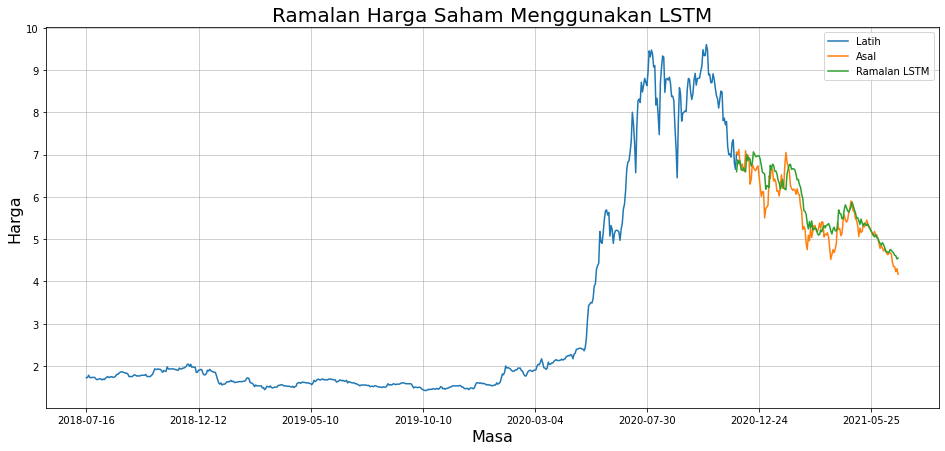

In [ ]:
# Add the date column
data_filtered_sub = data_filtered.copy()
data_filtered_sub['Date'] = date_index

# Add the difference between the valid and predicted prices
train = data_filtered_sub[:train_data_len + 1]
valid = data_filtered_sub[train_data_len:]
valid.insert(1, "Prediction", Y_pred.ravel(), True)
valid.insert(1, "Difference", valid["Prediction"] - valid["Price"], True)

# Visualize the data
plt.figure(figsize=(16,7))
plt.title('Ramalan Harga Saham Menggunakan LSTM', fontsize=20)
plt.xticks(np.arange(0,755,100))
plt.xlabel('Masa', fontsize=16)
plt.ylabel('Harga', fontsize=16)
plt.plot(train['Date'], train[["Price"]])
plt.plot(valid['Date'], valid[["Price", "Prediction"]])
plt.legend(['Latih', 'Asal', 'Ramalan LSTM'], loc='upper right')

# Plot the grid lines
plt.grid(which="major", color='#A3A3A3', linestyle='-', linewidth=0.5)
plt.show()

In [ ]:
train_df['Y_pred'] = np.NaN
train_df.iloc[(len(train_df) - len(Y_pred)):,-1:] = Y_pred
trade_data2 = train_df.dropna()
trade_data2

,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price,Y_pred
580,0.47,0.35,6.933333,7.172,8.205000,0.303183,7.05,6.595624
581,0.25,-0.11,6.833333,7.107,8.124000,0.265744,6.99,6.873506
582,0.28,0.10,6.896667,7.028,8.045667,0.193054,7.12,6.785690
583,0.47,-0.33,7.053333,7.020,7.971667,0.194679,6.79,6.848132
584,0.29,-0.05,6.966667,6.999,7.878000,0.184472,6.68,6.644509
...,...,...,...,...,...,...,...,...
720,0.16,-0.10,4.590000,4.679,5.002000,0.154855,4.35,4.674384
721,0.12,-0.01,4.483333,4.634,4.971667,0.157099,4.35,4.616172
722,0.15,-0.12,4.383333,4.597,4.944667,0.157099,4.23,4.607401
723,0.15,0.08,4.310000,4.543,4.913000,0.080498,4.30,4.531673


In [ ]:
trade_data2.describe()

,H-L,O-C,3day MA,10day MA,30day MA,Std_dev,Price,Y_pred
count,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000
mean,0.219379,-0.035655,5.666046,5.731931,5.960740,0.165058,5.630276,5.802560
std,0.125738,0.164206,0.737213,0.720893,0.838238,0.090307,0.754164,0.735418
min,0.070000,-0.600000,4.293333,4.499000,4.878000,0.025884,4.170000,4.531673
25%,0.140000,-0.120000,5.130000,5.170000,5.240333,0.091378,5.090000,5.236023
50%,0.180000,-0.040000,5.416667,5.518000,5.790667,0.154855,5.410000,5.636626
75%,0.260000,0.040000,6.310000,6.360000,6.436000,0.217325,6.250000,6.583251
max,0.880000,0.640000,7.053333,7.172000,8.205000,0.424594,7.120000,7.063041


In [ ]:
# Get the Root Mean Square Error (RMSE)
rmse = np.sqrt(np.mean(Y_pred - Y_test_unscaled) ** 2)

# Get the Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((Y_test_unscaled - Y_pred) / Y_test_unscaled)) * 100

print('RMSE (LSTM): {}'.format(rmse))
print('MAPE (LSTM): {}'.format(mape))

RMSE (LSTM): 0.17228409247562804
MAPE (LSTM): 4.548083620672921


In [ ]:
# Confusion Matrix (LSTM)
from sklearn.metrics import confusion_matrix
cutoff = 5.5                                   # decide on a cutoff limit
Y_pred_classes = np.zeros_like(Y_pred)    # initialise a matrix full with zeros
Y_pred_classes[Y_pred > cutoff] = 1       # add a 1 if the cutoff was breached

Y_test_classes = np.zeros_like(Y_pred)
Y_test_classes[Y_test_unscaled > cutoff] = 1

confusion_matrix(Y_test_classes, Y_pred_classes)

array([[67, 13],
       [ 0, 65]])

In [ ]:
from sklearn.metrics import confusion_matrix
Tp, Tn, Fp, Fn = confusion_matrix(Y_test_classes, Y_pred_classes).ravel()

print('True Positive :', Tp)
print('True Negative :', Tn)
print('False Positive :', Fp)
print('False Negative :', Fn)

True Positive : 67
True Negative : 13
False Positive : 0
False Negative : 65


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(Y_test_classes, Y_pred_classes))

              precision    recall  f1-score   support

         0.0       1.00      0.84      0.91        80
         1.0       0.83      1.00      0.91        65

    accuracy                           0.91       145
   macro avg       0.92      0.92      0.91       145
weighted avg       0.93      0.91      0.91       145



In [ ]:
print('LSTM')

from sklearn.metrics import accuracy_score
print('Accuracy :', 100 * accuracy_score(Y_test_classes, Y_pred_classes))

from sklearn.metrics import precision_score
print('Precision :', 100* precision_score(Y_test_classes, Y_pred_classes))

from sklearn.metrics import recall_score
print('Recall :', 100* recall_score(Y_test_classes, Y_pred_classes))

from sklearn.metrics import f1_score
print('F1 score :', f1_score(Y_test_classes, Y_pred_classes))

LSTM
Accuracy : 91.0344827586207
Precision : 83.33333333333334
Recall : 100.0
F1 score : 0.9090909090909091


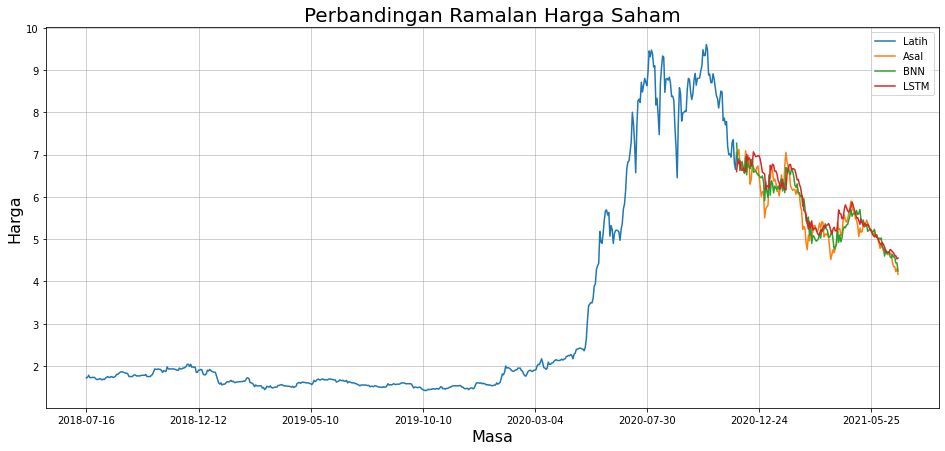

In [ ]:
# Add the date column
data_filtered_sub = data_filtered.copy()
data_filtered_sub['Date'] = date_index

# Add the difference between the valid and predicted prices
train = data_filtered_sub[:train_data_len + 1]
valid = data_filtered_sub[train_data_len:]
valid.insert(1, "Prediction_LSTM", Y_pred.ravel(), True)
valid.insert(1, "Difference", valid["Prediction_LSTM"] - valid["Price"], True)
valid.insert(1, "Prediction_BP", predictions.ravel(), True)
valid.insert(1, "Difference", valid["Prediction_BP"] - valid["Price"], True)

# Visualize the data
plt.figure(figsize=(16,7))
plt.title('Perbandingan Ramalan Harga Saham', fontsize=20)
plt.xticks(np.arange(0,755,100))
plt.xlabel('Masa', fontsize=16)
plt.ylabel('Harga', fontsize=16)
plt.plot(train['Date'], train[["Price"]])
plt.plot(valid['Date'], valid[["Price", "Prediction_BP","Prediction_LSTM"]])
plt.legend(['Latih', 'Asal', 'BNN', 'LSTM'], loc='upper right')

# Plot the grid lines
plt.grid(which="major", color='#A3A3A3', linestyle='-', linewidth=0.5)
plt.show()